In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Load the merged dataset stored locally in the notebooks folder
final_data = pd.read_csv("final_merged_data.csv")

# Check that it loaded correctly
final_data.shape

(392, 94)

## With original data

In [6]:
# Make copy that will be modified for use in analysis
df = final_data.copy()

# Identify each unique physical truck
df["Truck_ID"] = (
    df["Car"].astype(str) + "_" +
    df["Truck"].astype(str)
)

features = [
    "Eq Con 3mm",
    "Flange Width (Sd)_L",
    "Flange Width (Sd)_R",
    "Flange Height (Sh)_L",
    "Flange Height (Sh)_R",
    "Max Hollow Wear_L",
    "Max Hollow Wear_R",
    "Max Hollow Wear Position_L",
    "Max Hollow Wear Position_R",
    "Flange Radius_L",
    "Flange Radius_R"
]

# Confirm that target labels agree within each truck-rail group
group_cols = ["Truck_ID", "Rail_Profile"]

assert (
    df.groupby(group_cols)["Empty_Truck_Hunted"]
      .nunique(dropna=False)
      .eq(1).all()
), "Inconsistent hunting labels within truck-rail groups"

# Aggregate measurements from both axles
truck_df = (
    df.groupby(group_cols)
      .agg(
          {**{feature: "mean" for feature in features},
           "Empty_Truck_Hunted": "first"}
      )
      .reset_index()
)

In [7]:
# Add rail profile as a categorical predictor
X = truck_df[features + ["Rail_Profile"]].copy()
X = pd.get_dummies(
    X, columns=["Rail_Profile"], dtype=int
)

y = truck_df["Empty_Truck_Hunted"]
groups = truck_df["Truck_ID"]

# Remove incomplete observations for this initial baseline
valid = X.notna().all(axis=1) & y.notna()
X = X.loc[valid]
y = y.loc[valid]
groups = groups.loc[valid]

print("Class distribution:")
print(y.value_counts())

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv = GroupKFold(n_splits=5)

# Out-of-fold predictions
y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    groups=groups
)

print(classification_report(y, y_pred, zero_division=0))
print(confusion_matrix(y, y_pred))

Class distribution:
Empty_Truck_Hunted
True     126
False     70
Name: count, dtype: int64
              precision    recall  f1-score   support

       False       0.56      0.53      0.54        70
        True       0.75      0.77      0.76       126

    accuracy                           0.68       196
   macro avg       0.65      0.65      0.65       196
weighted avg       0.68      0.68      0.68       196

[[37 33]
 [29 97]]


## With the added average features

In [2]:
# Create wheelset hollow wear features from the left and right wheels
final_data["Hollow_Wear_Avg"] = (
    final_data["Max Hollow Wear - AAR_L"] +
    final_data["Max Hollow Wear - AAR_R"]
) / 2

final_data["Hollow_Wear_Diff"] = abs(
    final_data["Max Hollow Wear - AAR_L"] -
    final_data["Max Hollow Wear - AAR_R"]
)

# Create wheelset qR features from the left and right wheels
final_data["qR_Avg"] = (
    final_data["qR_L"] +
    final_data["qR_R"]
) / 2

final_data["qR_Diff"] = abs(
    final_data["qR_L"] -
    final_data["qR_R"]
)

# Create wheelset flange width features from the left and right wheels
final_data["Flange_Width_Avg"] = (
    final_data["Flange Width_L"] +
    final_data["Flange Width_R"]
) / 2

final_data["Flange_Width_Diff"] = abs(
    final_data["Flange Width_L"] -
    final_data["Flange Width_R"]
)

# Create wheelset maximum flange angle features
final_data["Flange_Angle_Avg"] = (
    final_data["Max Flange Angle_L"] +
    final_data["Max Flange Angle_R"]
) / 2

final_data["Flange_Angle_Diff"] = abs(
    final_data["Max Flange Angle_L"] -
    final_data["Max Flange Angle_R"]
)

# Create wheelset averages for the main wheel wear measurements
measurements = [
    "Flange Width (Sd)",
    "Flange Height (Sh)",
    "qR",
    "Flange Width",
    "Max Hollow Wear",
    "Flange Radius",
    "Max Flange Angle",
    "Min Flange Root Radius",
    "Max Hollow Wear - AAR"
]

for measurement in measurements:
    final_data[measurement + "_Avg"] = (
        final_data[measurement + "_L"] +
        final_data[measurement + "_R"]
    ) / 2

print("Dataset shape:", final_data.shape)

Dataset shape: (392, 110)


C:\Users\aaron\AppData\Local\Temp\ipykernel_24032\4239710233.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  final_data[measurement + "_Avg"] = (


In [3]:
# Make a copy for the Random Forest analysis
# Axles 1-2 belong to Truck 1; axles 3-4 belong to Truck 2.
truck_df = final_data.copy()

truck_df["Truck_ID"] = (
    truck_df["Car"].astype(str) + "_" + truck_df["Truck"].astype(str)
)

# Original wheel geometry and wheel-rail interaction predictors
features = [
    "Eq Con 3mm",
    "Flange Width (Sd)_L", "Flange Width (Sd)_R",
    "Flange Height (Sh)_L", "Flange Height (Sh)_R",
    "Max Hollow Wear_L", "Max Hollow Wear_R",
    "Max Hollow Wear Position_L", "Max Hollow Wear Position_R",
    "Flange Radius_L", "Flange Radius_R", 
    "Hollow_Wear_Avg", "Hollow_Wear_Diff",
    "qR_Avg", "qR_Diff",
    "Flange_Width_Avg", "Flange_Width_Diff",
    "Flange_Angle_Avg", "Flange_Angle_Diff",
    "Flange Width (Sd)_Avg",
    "Flange Height (Sh)_Avg",
    "Max Hollow Wear_Avg",
    "Flange Radius_Avg",
    "Min Flange Root Radius_Avg"
]

group_cols = ["Truck_ID", "Rail_Profile"]

# Confirm hunting outcomes agree across the two axles
assert (
    truck_df.groupby(group_cols)["Empty_Truck_Hunted"]
    .nunique(dropna=False).eq(1).all()
)

truck_df = (
    truck_df.groupby(group_cols)
    .agg({
        **{feature: "mean" for feature in features},
        "Empty_Truck_Hunted": "first"
    })
    .reset_index()
)

In [4]:
# Add rail profile as a categorical predictor
X = truck_df[features + ["Rail_Profile"]].copy()
X = pd.get_dummies(
    X, columns=["Rail_Profile"], dtype=int
)

y = truck_df["Empty_Truck_Hunted"]
groups = truck_df["Truck_ID"]

# Remove incomplete observations for this initial baseline
valid = X.notna().all(axis=1) & y.notna()
X = X.loc[valid]
y = y.loc[valid]
groups = groups.loc[valid]

print("Class distribution:")
print(y.value_counts())

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv = GroupKFold(n_splits=5)

# Out-of-fold predictions
y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    groups=groups
)

print(classification_report(y, y_pred, zero_division=0))
print(confusion_matrix(y, y_pred))

Class distribution:
Empty_Truck_Hunted
True     126
False     70
Name: count, dtype: int64
              precision    recall  f1-score   support

       False       0.53      0.39      0.45        70
        True       0.70      0.81      0.75       126

    accuracy                           0.66       196
   macro avg       0.62      0.60      0.60       196
weighted avg       0.64      0.66      0.64       196

[[ 27  43]
 [ 24 102]]


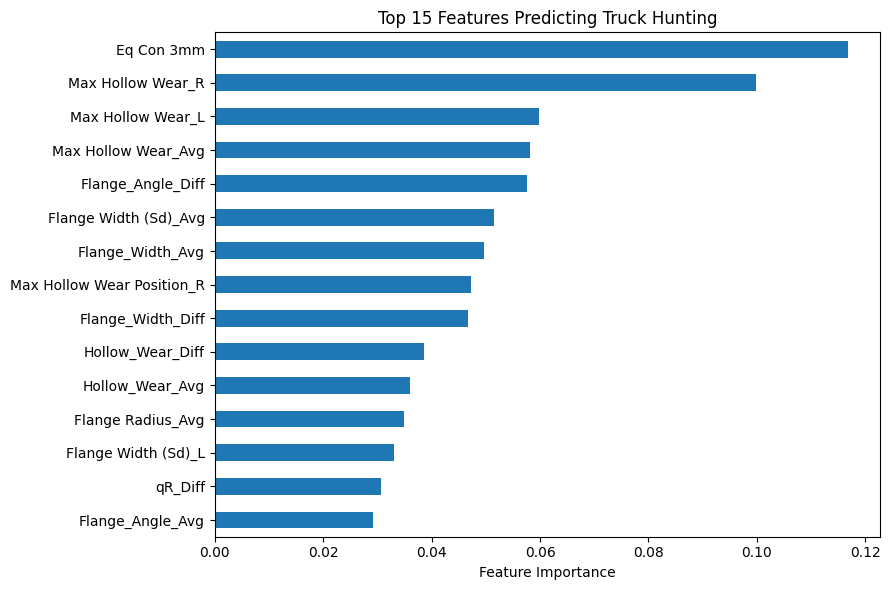

In [5]:
model.fit(X, y)

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features Predicting Truck Hunting")
plt.tight_layout()
plt.show()
